# Lab 12

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Questions

#### 1. Use the given code and modify for IRIS dataset. Implement the SVM classifier in Python (make use of `scikit-learn` library). Apply the linear kernel function. Plot the scatter plot of the input features. Plot the decision boundary.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data[:, :2]
y = iris.target

print(f"Feature names: {iris.feature_names[:2]}")
print(f"Target classes: {iris.target_names}")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Feature names: ['sepal length (cm)', 'sepal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 2)
Shape of y: (150,)


In [3]:
df = pd.DataFrame(X, columns=iris.feature_names[:2])
df["Species"] = iris.target_names[y]

df.head()

,sepal length (cm),sepal width (cm),Species
0,5.1,3.5,setosa
1,4.9,3.0,setosa
2,4.7,3.2,setosa
3,4.6,3.1,setosa
4,5.0,3.6,setosa


In [4]:
from sklearn.svm import SVC

svm = SVC(kernel="linear", C=1.0)
svm.fit(X, y)

print(f"Weights: {svm.coef_}")
print(f"Bias: {svm.intercept_}")
print(f"Number of support vectors: {svm.n_support_}")

Weights: [[-2.22720466  2.24959915]
 [-2.06931629  1.72277136]
 [-1.60096201 -0.79648515]]
Bias: [ 4.9417852   6.17860024 12.35500605]
Number of support vectors: [ 8 39 34]


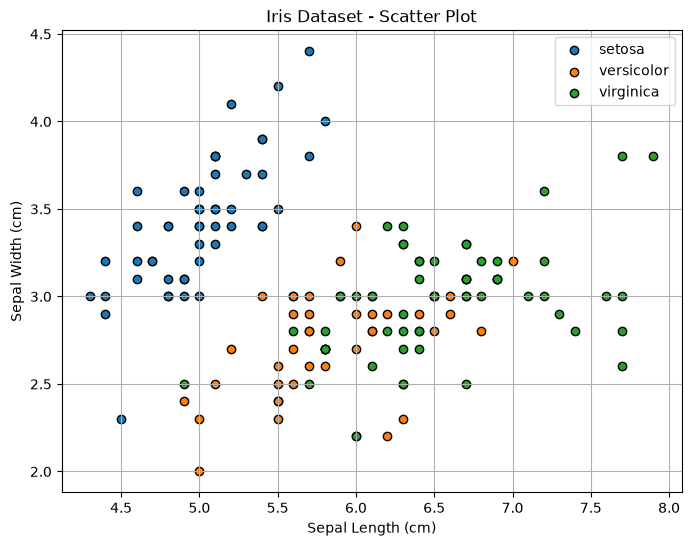

In [5]:
plt.figure(figsize=(8, 6))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=species,
        edgecolors="k"
    )

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Iris Dataset - Scatter Plot")
plt.legend()
plt.grid(True)
plt.show()

c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


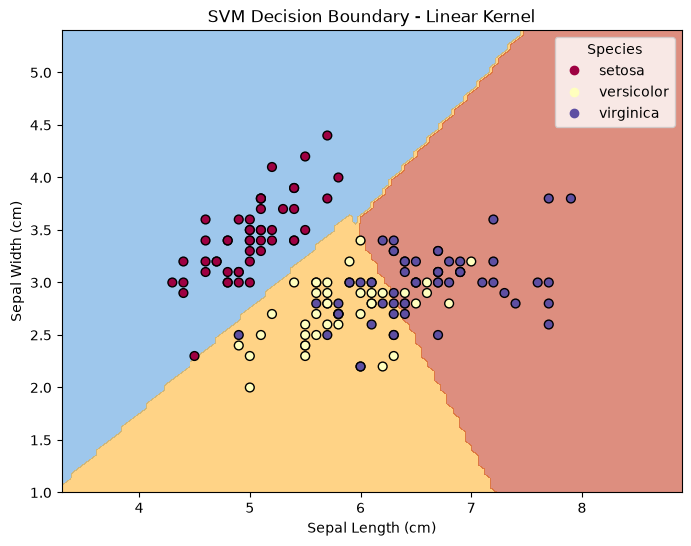

In [6]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm,
    X,
    response_method="predict",
    cmap=plt.cm.Spectral,
    alpha=0.5,
    ax=ax
)

scatter = ax.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap=plt.cm.Spectral,
    edgecolors="k",
    s=40
)

ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("SVM Decision Boundary - Linear Kernel")

handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names, title="Species")

plt.show()

#### 2. Construct a simple SVM classifier that separates the two classes: 
- Positively labeled data points: (4, 1), (4, -1), (6, 0) 
- Negatively labeled data points: (1, 0), (0, 1), (0, -1) 
- For all negatively labeled points, the output is -1, and for all positively labeled points, the output is 1.
#### Implement the python function program to draw the hyperplane that separates the two classes using `scikit-learn` library. Plot the scatter plot of the input features.

In [7]:
X = np.array([
    [4, 1],
    [4, -1],
    [6, 0],
    [1, 0],
    [0, 1],
    [0, -1]
])

y = np.array([1, 1, 1, -1, -1, -1])

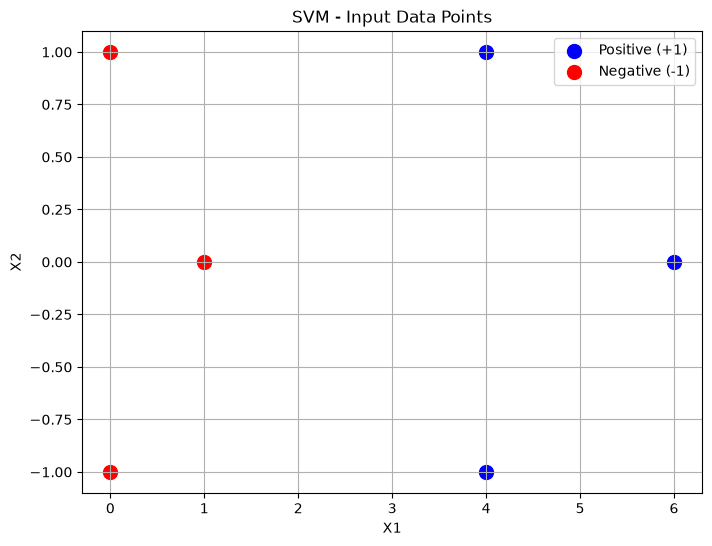

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Positive (+1)",
    s=100
)

plt.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    color="red",
    label="Negative (-1)",
    s=100
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM - Input Data Points")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
svm = SVC(kernel="linear", C=1e6)
svm.fit(X, y)

print(f"Weights: {svm.coef_}")
print(f"Bias: {svm.intercept_}")
print(f"Number of support vectors: {svm.n_support_}")

Weights: [[ 6.6675e-01 -2.5000e-04]]
Bias: [-1.66691667]
Number of support vectors: [1 2]


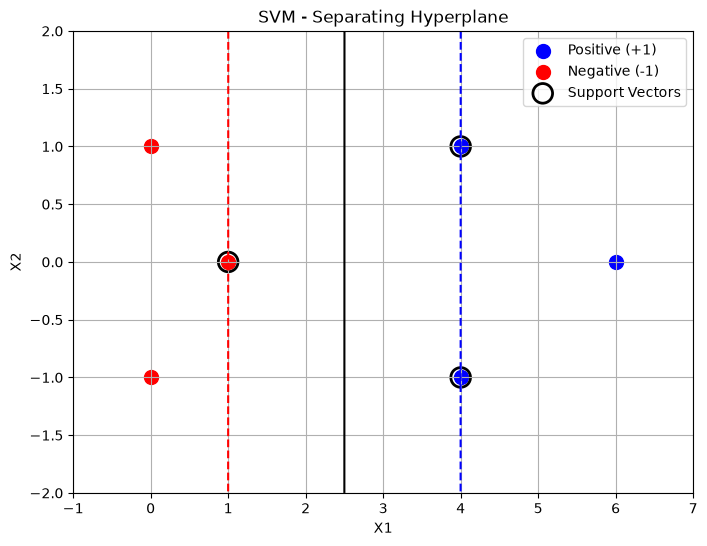

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm,
    X,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    colors=["red", "black", "blue"],
    linestyles=["--", "-", "--"],
    ax=ax
)

ax.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Positive (+1)",
    s=100
)

ax.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    color="red",
    label="Negative (-1)",
    s=100
)

ax.scatter(
    svm.support_vectors_[:, 0],
    svm.support_vectors_[:, 1],
    s=200,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("SVM - Separating Hyperplane")
ax.legend()
ax.grid(True)

plt.show()

In [11]:
w = svm.coef_[0]
b = svm.intercept_[0]

print(f"Hyperplane equation: {w[0]:.4f}x1 + {w[1]:.4f}x2 + ({b:.4f}) = 0")

print(f"\nSlope = {-w[0] / w[1] if abs(w[1]) > 1e-10 else 'Undefined (vertical line)'}")
print(f"Support Vector Indices: {svm.support_}")

Hyperplane equation: 0.6667x1 + -0.0003x2 + (-1.6669) = 0

Slope = 2666.9999999998495
Support Vector Indices: [3 0 1]


#### 3. Solve Qn (2) manually in your Observation book and implement without using `scikit-learn` library.

In [12]:
X = np.array([
    [4, 1],
    [4, -1],
    [6, 0],
    [1, 0],
    [0, 1],
    [0, -1]
], dtype=float)

y = np.array([1, 1, 1, -1, -1, -1])

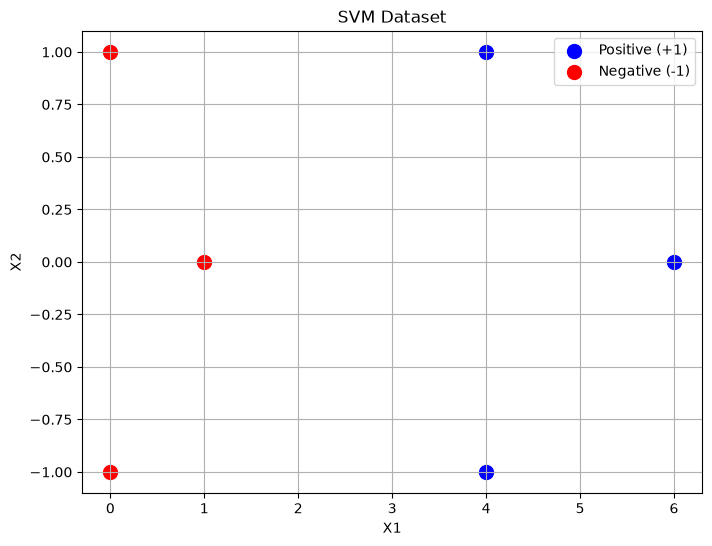

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color="blue",
    label="Positive (+1)",
    s=100
)

plt.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    color="red",
    label="Negative (-1)",
    s=100
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
positive = X[y == 1]
negative = X[y == -1]

positive_boundary = np.min(positive[:, 0])
negative_boundary = np.max(negative[:, 0])

boundary = (positive_boundary + negative_boundary) / 2
margin = (positive_boundary - negative_boundary) / 2

w = np.array([1 / margin, 0])
b = -boundary / margin

print(f"Positive boundary: {positive_boundary}")
print(f"Negative boundary: {negative_boundary}")

print(f"Optimal boundary: x1 = {boundary}")
print(f"Weight vector: {w}")
print(f"Bias: {b}")
print(f"Geometric margin: {margin}")

Positive boundary: 4.0
Negative boundary: 1.0
Optimal boundary: x1 = 2.5
Weight vector: [0.66666667 0.        ]
Bias: -1.6666666666666667
Geometric margin: 1.5


In [15]:
decision_values = X @ w + b

support_indices = np.where(
    np.isclose(y * decision_values, 1)
)[0]

support_vectors = X[support_indices]

print(f"Support Vector Indices: {support_indices}")
print(f"Support Vectors:\n{support_vectors}")

Support Vector Indices: [0 1 3]
Support Vectors:
[[ 4.  1.]
 [ 4. -1.]
 [ 1.  0.]]


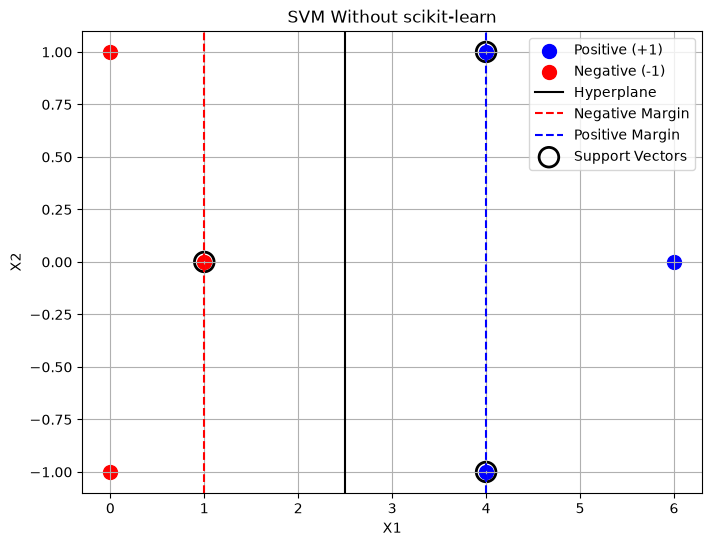

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    positive[:, 0],
    positive[:, 1],
    color="blue",
    s=100,
    label="Positive (+1)"
)

plt.scatter(
    negative[:, 0],
    negative[:, 1],
    color="red",
    s=100,
    label="Negative (-1)"
)

plt.axvline(
    boundary,
    color="black",
    label="Hyperplane"
)

plt.axvline(
    negative_boundary,
    color="red",
    linestyle="--",
    label="Negative Margin"
)

plt.axvline(
    positive_boundary,
    color="blue",
    linestyle="--",
    label="Positive Margin"
)

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=200,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="Support Vectors"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Without scikit-learn")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
def predict_svm(X_test):
    X_test = np.atleast_2d(X_test)
    scores = X_test @ w + b
    return np.where(scores >= 0, 1, -1)

In [18]:
X_test = np.array([
    [5, 0],
    [0, 0],
    [3, 1],
    [2, -1]
])

predictions = predict_svm(X_test)

for point, prediction in zip(X_test, predictions):
    print(f"{point} -> Class {prediction}")

[5 0] -> Class 1
[0 0] -> Class -1
[3 1] -> Class 1
[ 2 -1] -> Class -1


#### 4. Develop a Python function program to sketch the hyperplane 1 + 2X1 + 3X2 = 0 without using `scikit-learn` library. Indicate the set of points for which 1 + 3X1 − X2 > 0, 1 + 3X1 − X2 < 0 and 1 + 3X1 − X2=0. Take x1, x2 ∈ (-10, 10). Plot the graph for every +/- 1 increment. Find the slope and intercept. Solve manually in your Observation book. Compare your results with manual results.

In [19]:
def hyperplane1(x1):
    return -(1 + 2*x1) / 3

def hyperplane2(x1):
    return 1 + 3*x1

In [20]:
x1 = np.arange(-9, 10, 1)
x2 = np.arange(-9, 10, 1)

X1, X2 = np.meshgrid(x1, x2)

Z = 1 + 3*X1 - X2

positive = Z > 0
negative = Z < 0
zero = Z == 0

print(f"Positive points: {np.sum(positive)}")
print(f"Negative points: {np.sum(negative)}")
print(f"Zero points: {np.sum(zero)}")

Positive points: 184
Negative points: 171
Zero points: 6


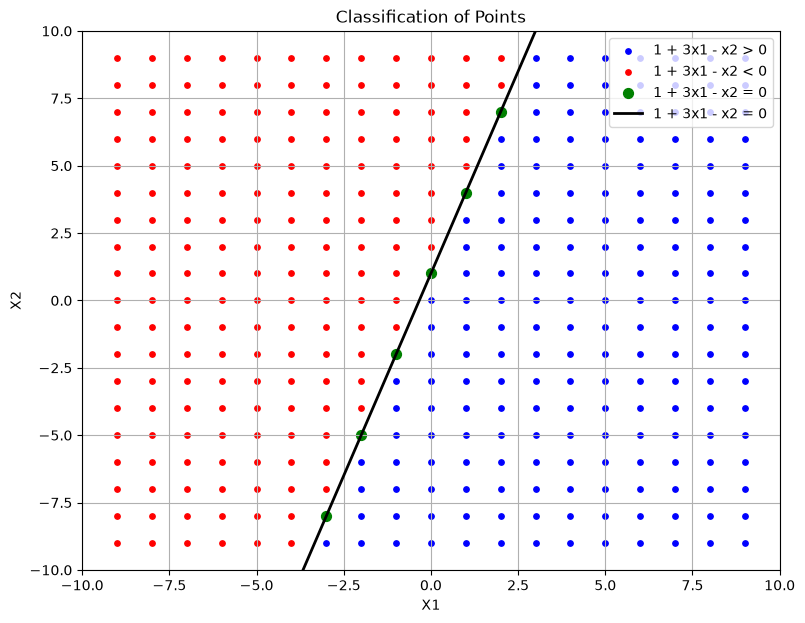

In [21]:
plt.figure(figsize=(9, 7))

plt.scatter(
    X1[positive],
    X2[positive],
    color="blue",
    s=15,
    label="1 + 3x1 - x2 > 0"
)

plt.scatter(
    X1[negative],
    X2[negative],
    color="red",
    s=15,
    label="1 + 3x1 - x2 < 0"
)

plt.scatter(
    X1[zero],
    X2[zero],
    color="green",
    s=50,
    label="1 + 3x1 - x2 = 0"
)

x = np.linspace(-10, 10, 400)

plt.plot(
    x,
    hyperplane2(x),
    color="black",
    linewidth=2,
    label="1 + 3x1 - x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Classification of Points")

plt.legend()
plt.grid(True)
plt.show()

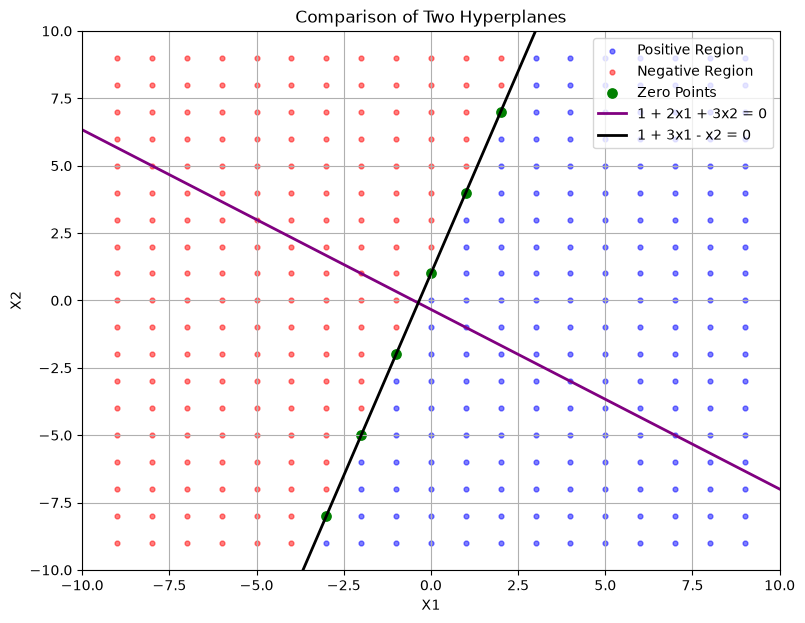

In [22]:
x = np.linspace(-10, 10, 400)

plt.figure(figsize=(9, 7))

plt.scatter(
    X1[positive], X2[positive],
    color="blue", s=12, alpha=0.5,
    label="Positive Region"
)

plt.scatter(
    X1[negative], X2[negative],
    color="red", s=12, alpha=0.5,
    label="Negative Region"
)

plt.scatter(
    X1[zero], X2[zero],
    color="green", s=45,
    label="Zero Points"
)

plt.plot(
    x, hyperplane1(x),
    color="purple", linewidth=2,
    label="1 + 2x1 + 3x2 = 0"
)

plt.plot(
    x, hyperplane2(x),
    color="black", linewidth=2,
    label="1 + 3x1 - x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Comparison of Two Hyperplanes")

plt.legend()
plt.grid(True)
plt.show()

In [23]:
def calc_coefficients(a, b, c):
    slope = -a / b
    intercept = -c / b
    return slope, intercept

m1, c1 = calc_coefficients(2, 3, 1)
m2, c2 = calc_coefficients(3, -1, 1)

print("Hyperplane 1:")
print(f"Slope = {m1}")
print(f"Y-intercept = {c1}")

print("\nHyperplane 2:")
print(f"Slope = {m2}")
print(f"Y-intercept = {c2}")

Hyperplane 1:
Slope = -0.6666666666666666
Y-intercept = -0.3333333333333333

Hyperplane 2:
Slope = 3.0
Y-intercept = 1.0


In [24]:
df = pd.DataFrame({
    "X1": X1.ravel(),
    "X2": X2.ravel(),
    "Value": Z.ravel()
})

df["Region"] = np.where(
    df["Value"] > 0, "Positive",
    np.where(df["Value"] < 0, "Negative", "Zero")
)

display(df.head())
print(df["Region"].value_counts())

,X1,X2,Value,Region
0,-9,-9,-17,Negative
1,-8,-9,-14,Negative
2,-7,-9,-11,Negative
3,-6,-9,-8,Negative
4,-5,-9,-5,Negative


Region
Positive    184
Negative    171
Zero          6
Name: count, dtype: int64


#### 5. Given two hyperplanes for SVM classifier 1 and SVM classifier 2, find the best hyperplane corresponding to the classifier:
- 5+2x1+5x2
- 5+20x1+50x2
#### Implement Python function program to draw the hyperplane that separates the two classes (without `scikit-learn` library). Plot the scatter plot of the input features. Indicate the set of points for which `5+2*x1+ 5*x2 > 0`, `5+2*x1+ 5*x2 < 0`, and `5+2*x1+ 5*x2 = 0`. On the same plot, indicate the set of points for which `5+20*x1+50*x2 > 0`, `5+20*x1+50*x2 < 0`, and `5+20*x1+50*x2 = 0`. Find the slope and intercept. Solve manually in your Observation book. Compare your results with manual results.

In [25]:
def hyperplane1(x1, x2):
    return 5 + 2*x1 + 5*x2

def hyperplane2(x1, x2):
    return 5 + 20*x1 + 50*x2

In [26]:
x1 = np.arange(-10, 11, 1)
x2 = np.arange(-10, 11, 1)

X1, X2 = np.meshgrid(x1, x2)

Z1 = hyperplane1(X1, X2)
Z2 = hyperplane2(X1, X2)

print(f"Total points: {X1.size}")

Total points: 441


In [27]:
positive1 = Z1 > 0
negative1 = Z1 < 0
zero1 = np.isclose(Z1, 0)

print("Hyperplane 1:")
print(f"Positive points: {np.sum(positive1)}")
print(f"Negative points: {np.sum(negative1)}")
print(f"Zero points: {np.sum(zero1)}")

Hyperplane 1:
Positive points: 239
Negative points: 197
Zero points: 5


In [28]:
positive2 = Z2 > 0
negative2 = Z2 < 0
zero2 = np.isclose(Z2, 0)

print("Hyperplane 2:")
print(f"Positive points: {np.sum(positive2)}")
print(f"Negative points: {np.sum(negative2)}")
print(f"Zero points: {np.sum(zero2)}")

Hyperplane 2:
Positive points: 223
Negative points: 218
Zero points: 0


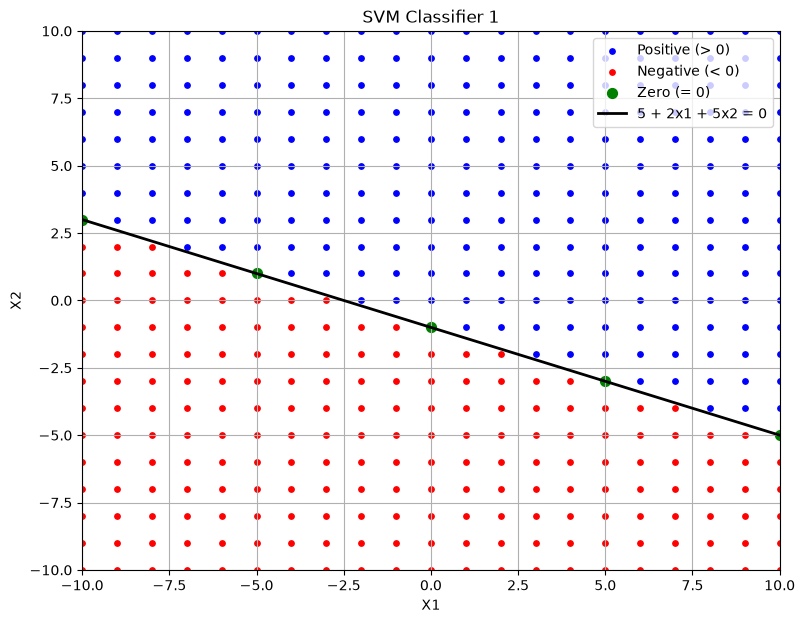

In [29]:
x = np.linspace(-10, 10, 400)

y1 = -(5 + 2*x) / 5

plt.figure(figsize=(9, 7))

plt.scatter(
    X1[positive1], X2[positive1],
    color="blue", s=15,
    label="Positive (> 0)"
)

plt.scatter(
    X1[negative1], X2[negative1],
    color="red", s=15,
    label="Negative (< 0)"
)

plt.scatter(
    X1[zero1], X2[zero1],
    color="green", s=50,
    label="Zero (= 0)"
)

plt.plot(
    x, y1,
    color="black", linewidth=2,
    label="5 + 2x1 + 5x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Classifier 1")

plt.legend()
plt.grid(True)
plt.show()

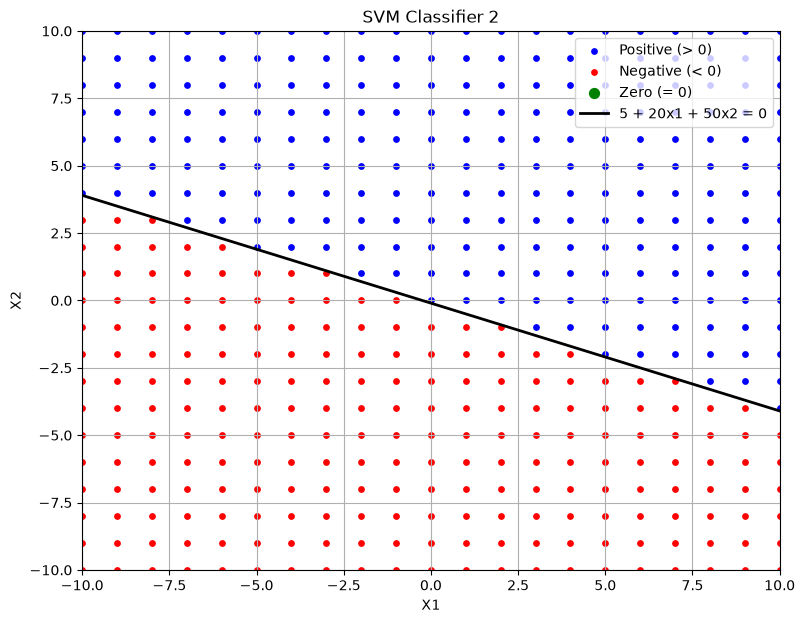

In [30]:
y2 = -(5 + 20*x) / 50

plt.figure(figsize=(9, 7))

plt.scatter(
    X1[positive2], X2[positive2],
    color="blue", s=15,
    label="Positive (> 0)"
)

plt.scatter(
    X1[negative2], X2[negative2],
    color="red", s=15,
    label="Negative (< 0)"
)

plt.scatter(
    X1[zero2], X2[zero2],
    color="green", s=50,
    label="Zero (= 0)"
)

plt.plot(
    x, y2,
    color="black", linewidth=2,
    label="5 + 20x1 + 50x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Classifier 2")

plt.legend()
plt.grid(True)
plt.show()

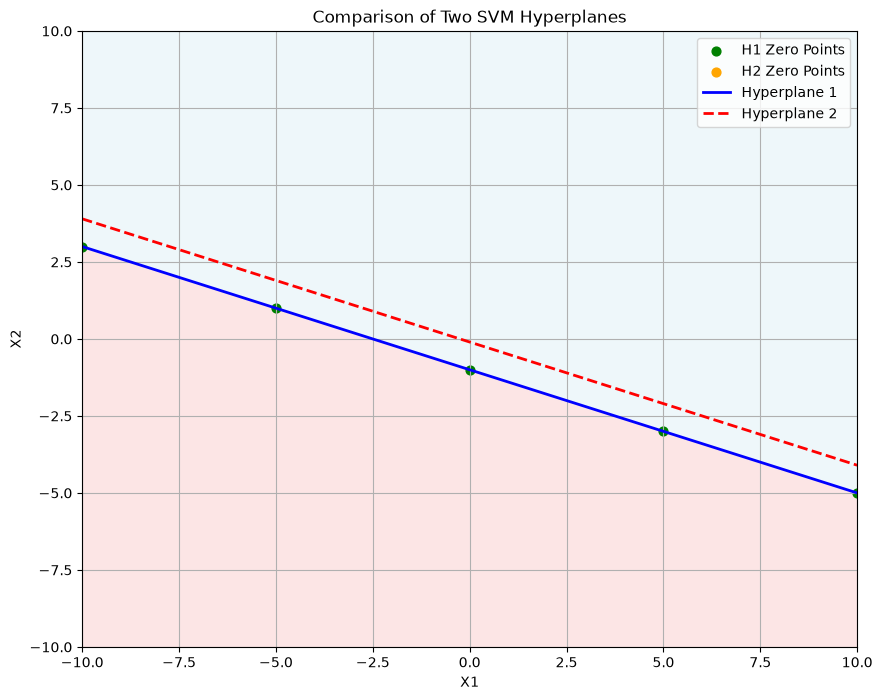

In [31]:
plt.figure(figsize=(10, 8))

plt.contourf(
    X1, X2, Z1,
    levels=[-300, 0, 300],
    colors=["lightcoral", "lightblue"],
    alpha=0.2
)

plt.scatter(
    X1[zero1], X2[zero1],
    color="green", s=40,
    label="H1 Zero Points"
)

plt.scatter(
    X1[zero2], X2[zero2],
    color="orange", s=40,
    label="H2 Zero Points"
)

plt.plot(
    x, y1,
    color="blue", linewidth=2,
    label="Hyperplane 1"
)

plt.plot(
    x, y2,
    color="red", linewidth=2,
    linestyle="--",
    label="Hyperplane 2"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Comparison of Two SVM Hyperplanes")

plt.legend()
plt.grid(True)
plt.show()

In [32]:
def calc_coefficients(a, b, c):
    slope = -a / b
    y_intercept = -c / b
    x_intercept = -c / a

    return slope, y_intercept, x_intercept

m1, c1, x_int1 = calc_coefficients(2, 5, 5)
m2, c2, x_int2 = calc_coefficients(20, 50, 5)

print("Hyperplane 1:")
print(f"Slope = {m1}")
print(f"Y-intercept = {c1}")
print(f"X-intercept: {x_int1}")

print("\nHyperplane 2:")
print(f"Slope = {m2}")
print(f"Y-intercept = {c2}")
print(f"X-intercept = {x_int2}")

Hyperplane 1:
Slope = -0.4
Y-intercept = -1.0
X-intercept: -2.5

Hyperplane 2:
Slope = -0.4
Y-intercept = -0.1
X-intercept = -0.25


## Additional questions

#### 1. Given two hyperplanes for SVM classifier 1 and SVM classifier 2, find the best hyperplane corresponding to the classifier:
- 5+2x1+5x2
- 5+20x1+50x2
#### Implement the python function program to draw the hyperplane that separates the two classes (make use of `scikit-learn` libray). Plot the scatter plot of the input features. Indicate the set of points for which `5+2*x1+ 5*x2 > 0`, `5+2*x1+ 5*x2 < 0`, and `5+2*x1+ 5*x2 = 0`. On the same plot, indicate the set of points for which `5+20*x1+50*x2 > 0`, `5+20*x1+50*x2 < 0`, and `5+20*x1+50*x2 = 0`.

In [33]:
w1 = np.array([2, 5])
b1 = 5

w2 = np.array([20, 50])
b2 = 5

In [34]:
def hyperplane(X, w, b):
    return X @ w + b

In [35]:
x1 = np.arange(-10, 11, 1)
x2 = np.arange(-10, 11, 1)

X1, X2 = np.meshgrid(x1, x2)
X = np.column_stack((X1.ravel(), X2.ravel()))

print(f"Total points: {len(X)}")
print(X[:10])

Total points: 441
[[-10 -10]
 [ -9 -10]
 [ -8 -10]
 [ -7 -10]
 [ -6 -10]
 [ -5 -10]
 [ -4 -10]
 [ -3 -10]
 [ -2 -10]
 [ -1 -10]]


In [36]:
from sklearn.svm import LinearSVC

svm1 = LinearSVC()
svm2 = LinearSVC()

svm1.coef_ = w1.reshape(1, -1)
svm1.intercept_ = np.array([b1])
svm1.classes_ = np.array([-1, 1])
svm1.n_features_in_ = 2

svm2.coef_ = w2.reshape(1, -1)
svm2.intercept_ = np.array([b2])
svm2.classes_ = np.array([-1, 1])
svm2.n_features_in_ = 2

print(f"SVM 1 weights: {svm1.coef_}")
print(f"SVM 1 bias: {svm1.intercept_}")

print(f"\nSVM 2 weights: {svm2.coef_}")
print(f"SVM 2 bias: {svm2.intercept_}")

SVM 1 weights: [[2 5]]
SVM 1 bias: [5]

SVM 2 weights: [[20 50]]
SVM 2 bias: [5]


In [37]:
Z1 = svm1.decision_function(X)

positive1 = Z1 > 0
negative1 = Z1 < 0
zero1 = np.isclose(Z1, 0)

print("Hyperplane 1:")
print(f"Positive points: {np.sum(positive1)}")
print(f"Negative points: {np.sum(negative1)}")
print(f"Zero points: {np.sum(zero1)}")

Hyperplane 1:
Positive points: 239
Negative points: 197
Zero points: 5


In [38]:
Z2 = svm2.decision_function(X)

positive2 = Z2 > 0
negative2 = Z2 < 0
zero2 = np.isclose(Z2, 0)

print("Hyperplane 2:")
print(f"Positive points: {np.sum(positive2)}")
print(f"Negative points: {np.sum(negative2)}")
print(f"Zero points: {np.sum(zero2)}")

Hyperplane 2:
Positive points: 223
Negative points: 218
Zero points: 0


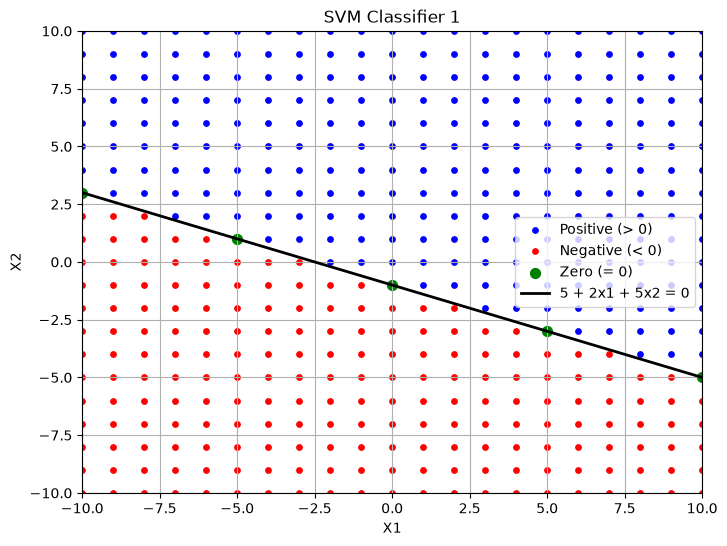

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[positive1, 0], X[positive1, 1],
    color="blue", s=15, label="Positive (> 0)"
)

plt.scatter(
    X[negative1, 0], X[negative1, 1],
    color="red", s=15, label="Negative (< 0)"
)

plt.scatter(
    X[zero1, 0], X[zero1, 1],
    color="green", s=50, label="Zero (= 0)"
)

x = np.linspace(-10, 10, 400)
y1 = -(5 + 2*x) / 5

plt.plot(
    x, y1,
    color="black", linewidth=2,
    label="5 + 2x1 + 5x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Classifier 1")

plt.legend()
plt.grid(True)
plt.show()

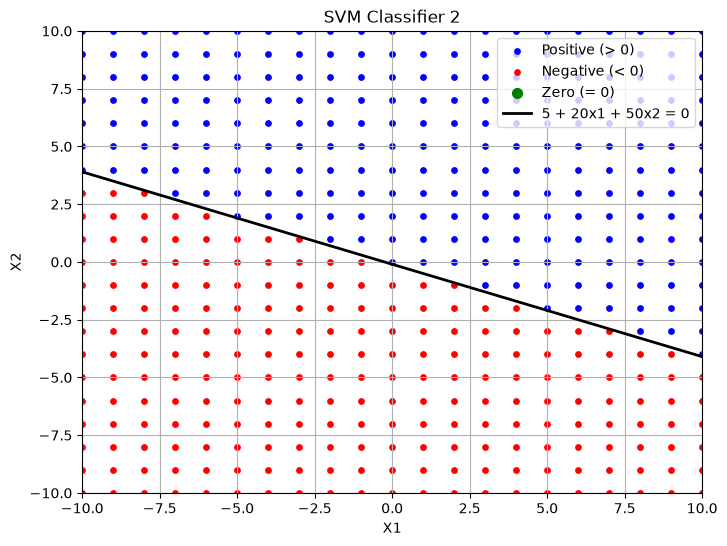

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[positive2, 0], X[positive2, 1],
    color="blue", s=15, label="Positive (> 0)"
)

plt.scatter(
    X[negative2, 0], X[negative2, 1],
    color="red", s=15, label="Negative (< 0)"
)

plt.scatter(
    X[zero2, 0], X[zero2, 1],
    color="green", s=50, label="Zero (= 0)"
)

y2 = -(5 + 20*x) / 50

plt.plot(
    x, y2,
    color="black", linewidth=2,
    label="5 + 20x1 + 50x2 = 0"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("SVM Classifier 2")

plt.legend()
plt.grid(True)
plt.show()

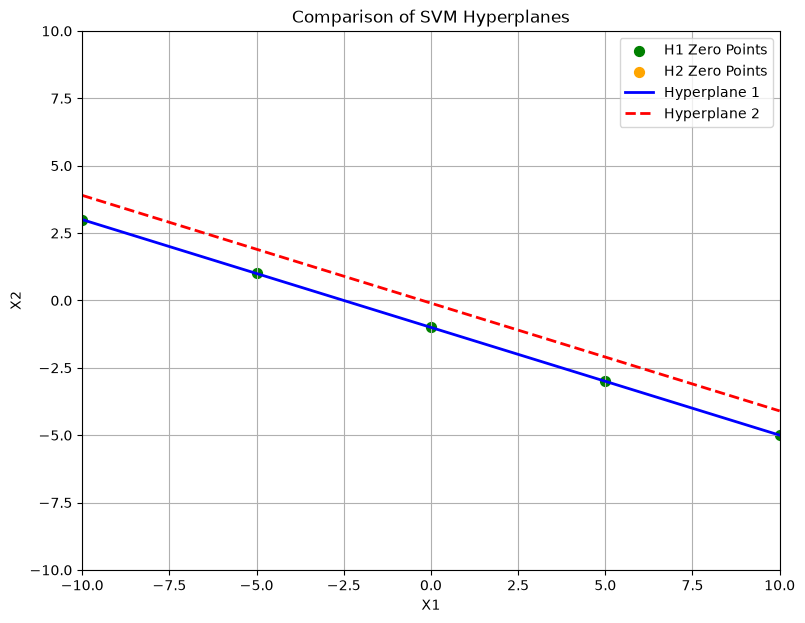

In [41]:
plt.figure(figsize=(9, 7))

plt.scatter(
    X[zero1, 0], X[zero1, 1],
    color="green", s=50,
    label="H1 Zero Points"
)

plt.scatter(
    X[zero2, 0], X[zero2, 1],
    color="orange", s=50,
    label="H2 Zero Points"
)

plt.plot(
    x, y1,
    color="blue", linewidth=2,
    label="Hyperplane 1"
)

plt.plot(
    x, y2,
    color="red", linewidth=2,
    linestyle="--",
    label="Hyperplane 2"
)

plt.xlim(-10, 10)
plt.ylim(-10, 10)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Comparison of SVM Hyperplanes")

plt.legend()
plt.grid(True)
plt.show()

In [42]:
pred1 = svm1.predict(X)
pred2 = svm2.predict(X)

agreement = np.mean(pred1 == pred2) * 100

print(f"Prediction agreement: {agreement}%")
print(f"Different predictions: {np.sum(pred1 != pred2)}")

Prediction agreement: 96.3718820861678%
Different predictions: 16


In [43]:
def calc_coefficients(w, b):
    slope = -w[0] / w[1]
    y_intercept = -b / w[1]
    x_intercept = -b / w[0]

    return slope, y_intercept, x_intercept

m1, c1, x_int1 = calc_coefficients(w1, b1)
m2, c2, x_int2 = calc_coefficients(w2, b2)

print("Hyperplane 1:")
print(f"Slope: {m1}")
print(f"Y-intercept: {c1}")
print(f"X-intercept: {x_int1}")

print("\nHyperplane 2:")
print(f"Slope: {m2}")
print(f"Y-intercept: {c2}")
print(f"X-intercept: {x_int2}")

Hyperplane 1:
Slope: -0.4
Y-intercept: -1.0
X-intercept: -2.5

Hyperplane 2:
Slope: -0.4
Y-intercept: -0.1
X-intercept: -0.25


#### 2. Use the IRIS dataset, implement the SVM classifier in Python (make use of `scikit-learn` library), to do the following. 
- Apply the kernel functions such as linear, polynomial, Radial basis functions and Sigmoid.
- Plot the scatter plot of the input features.
- Plot the decision boundary.

In [44]:
iris = load_iris()

X = iris.data[:, :2]
y = iris.target

print(f"Features: {iris.feature_names[:2]}")
print(f"Classes: {iris.target_names}")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Features: ['sepal length (cm)', 'sepal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 2)
Shape of y: (150,)


In [45]:
df = pd.DataFrame(
    X,
    columns=iris.feature_names[:2]
)

df["Species"] = iris.target_names[y]
df.head()

,sepal length (cm),sepal width (cm),Species
0,5.1,3.5,setosa
1,4.9,3.0,setosa
2,4.7,3.2,setosa
3,4.6,3.1,setosa
4,5.0,3.6,setosa


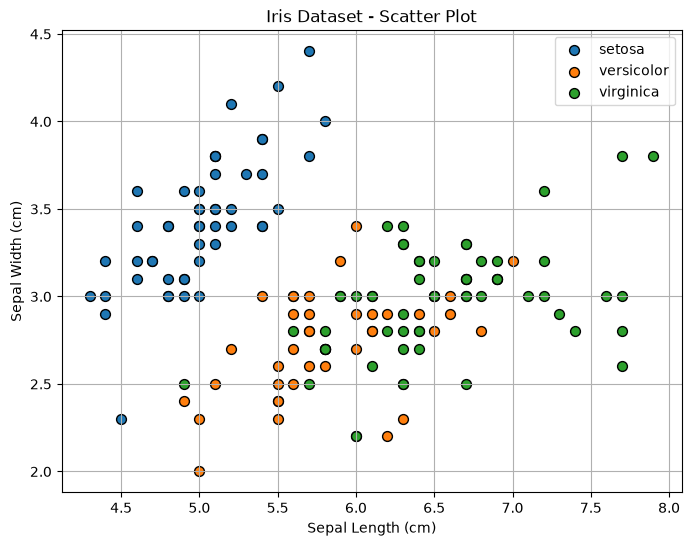

In [46]:
plt.figure(figsize=(8, 6))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=species,
        s=50,
        edgecolors="black"
    )

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Iris Dataset - Scatter Plot")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
svm_linear = SVC(kernel="linear", C=1.0)
svm_linear.fit(X, y)

print(f"Support vectors: {svm_linear.n_support_}")
print(f"Training accuracy: {svm_linear.score(X, y)}")

Support vectors: [ 8 39 34]
Training accuracy: 0.82


c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


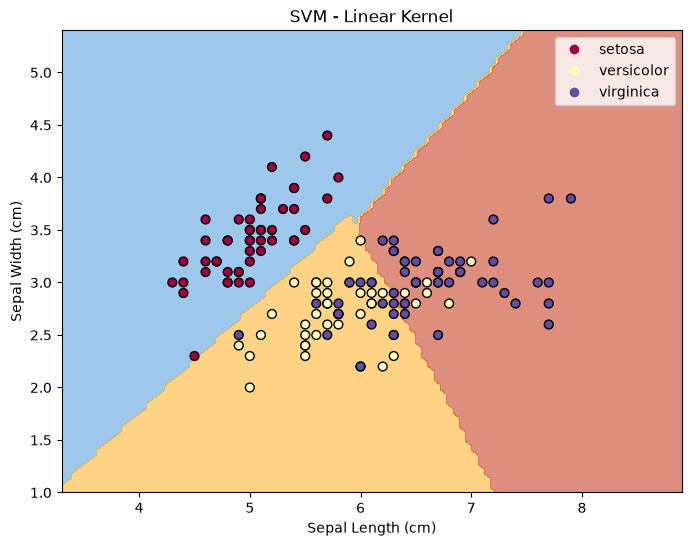

In [48]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_linear,
    X,
    response_method="predict",
    cmap=plt.cm.Spectral,
    alpha=0.5,
    ax=ax
)

scatter = ax.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap=plt.cm.Spectral,
    edgecolors="black",
    s=40
)

ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("SVM - Linear Kernel")

handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names)

plt.show()

In [49]:
svm_poly = SVC(
    kernel="poly",
    degree=3,
    C=1.0
)

svm_poly.fit(X, y)

print(f"Support vectors: {svm_poly.n_support_}")
print(f"Training accuracy: {svm_poly.score(X, y)}")

Support vectors: [ 2 34 34]
Training accuracy: 0.8133333333333334


c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


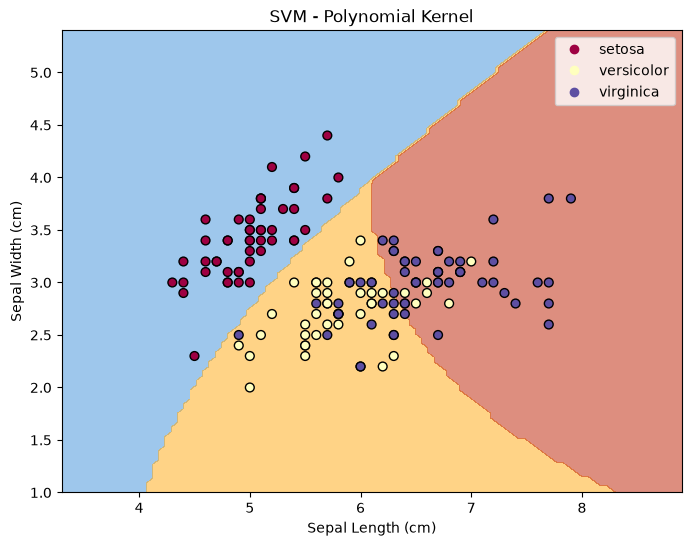

In [50]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_poly,
    X,
    response_method="predict",
    cmap=plt.cm.Spectral,
    alpha=0.5,
    ax=ax
)

scatter = ax.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap=plt.cm.Spectral,
    edgecolors="black",
    s=40
)

ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("SVM - Polynomial Kernel")

handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names)

plt.show()

In [51]:
svm_rbf = SVC(
    kernel="rbf",
    gamma="scale",
    C=1.0
)

svm_rbf.fit(X, y)

print(f"Support vectors: {svm_rbf.n_support_}")
print(f"Training accuracy: {svm_rbf.score(X, y)}")

Support vectors: [14 43 37]
Training accuracy: 0.82


c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


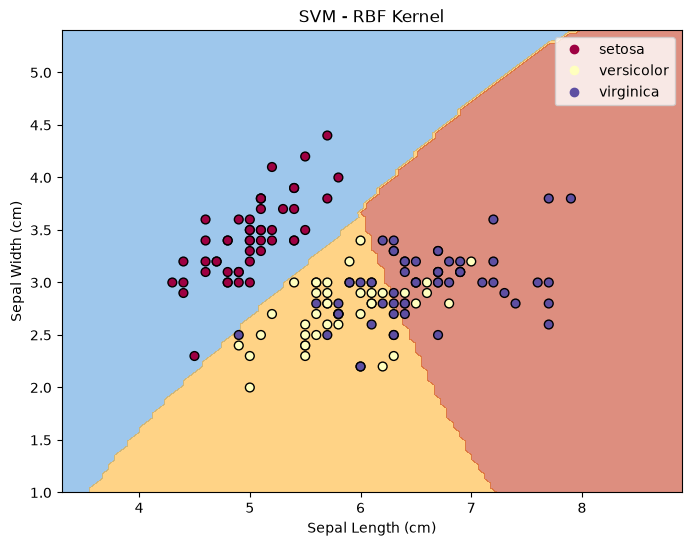

In [52]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_rbf,
    X,
    response_method="predict",
    cmap=plt.cm.Spectral,
    alpha=0.5,
    ax=ax
)

scatter = ax.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap=plt.cm.Spectral,
    edgecolors="black",
    s=40
)

ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("SVM - RBF Kernel")

handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names)

plt.show()

In [53]:
svm_sigmoid = SVC(
    kernel="sigmoid",
    gamma="scale",
    C=1.0
)

svm_sigmoid.fit(X, y)

print(f"Support vectors: {svm_sigmoid.n_support_}")
print(f"Training accuracy: {svm_sigmoid.score(X, y)}")

Support vectors: [50 50 50]
Training accuracy: 0.24666666666666667


c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


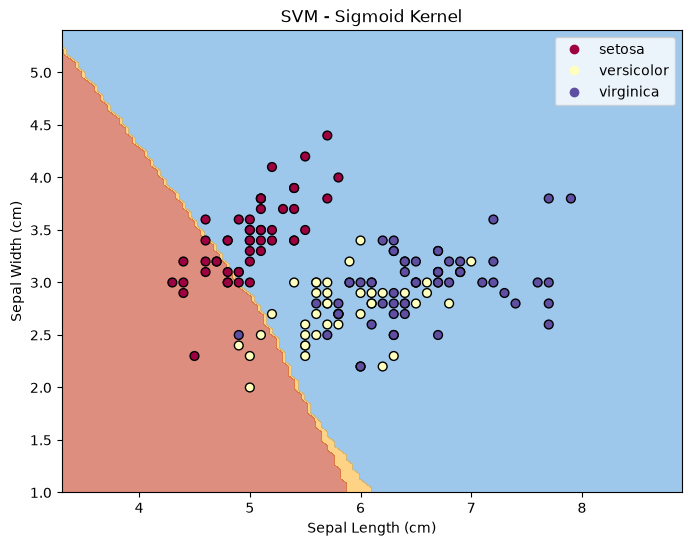

In [54]:
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_sigmoid,
    X,
    response_method="predict",
    cmap=plt.cm.Spectral,
    alpha=0.5,
    ax=ax
)

scatter = ax.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap=plt.cm.Spectral,
    edgecolors="black",
    s=40
)

ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("SVM - Sigmoid Kernel")

handles, _ = scatter.legend_elements()
ax.legend(handles, iris.target_names)

plt.show()

c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
c:\Users\ghanti\dev\sem5\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


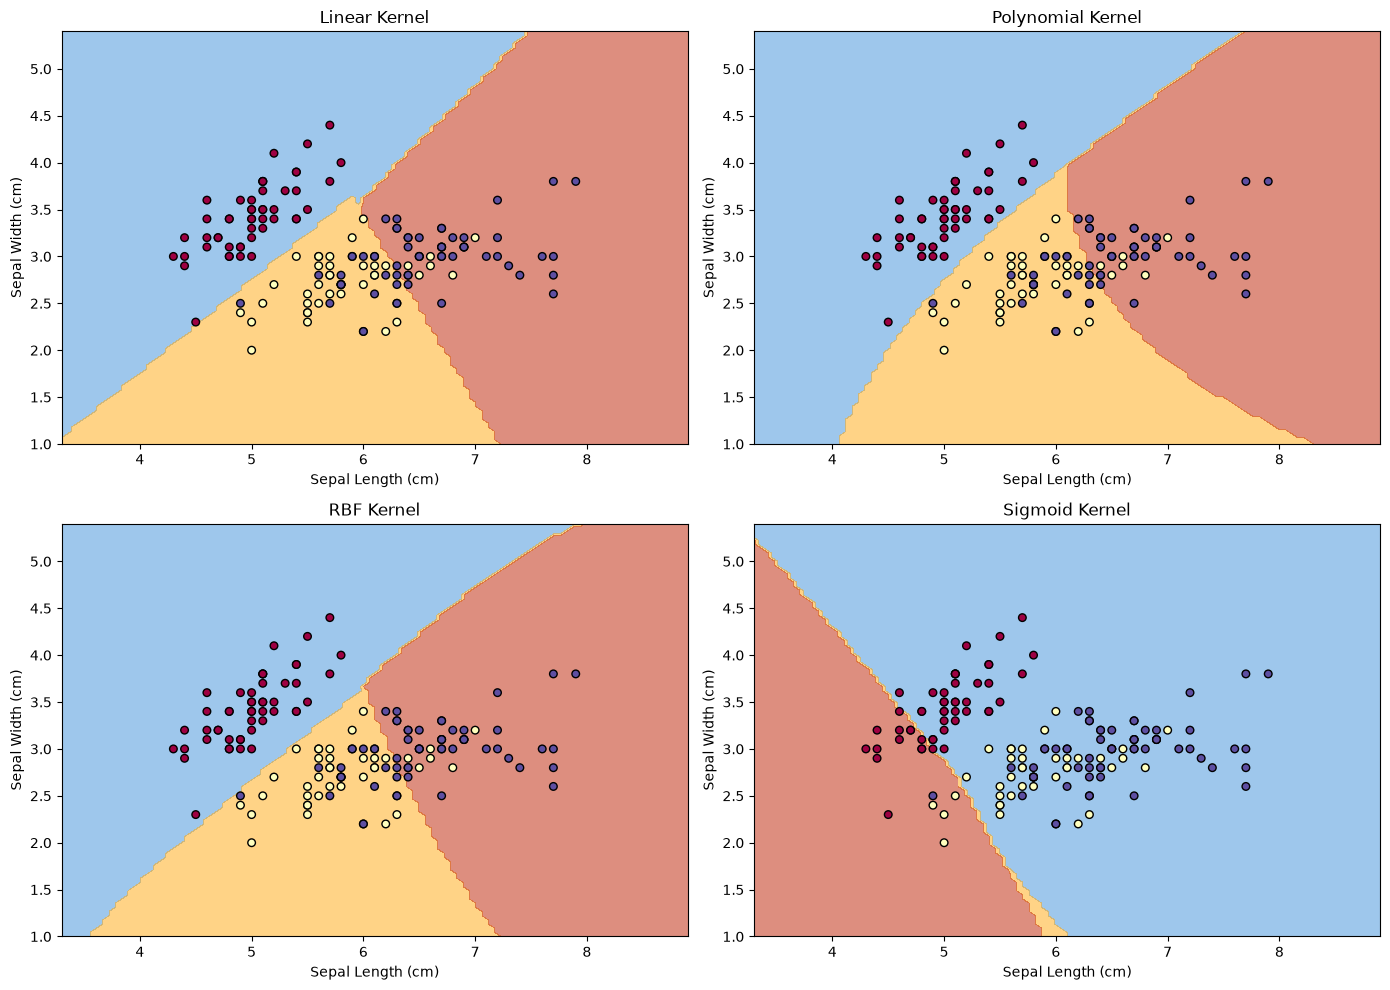

In [55]:
models = {
    "Linear": svm_linear,
    "Polynomial": svm_poly,
    "RBF": svm_rbf,
    "Sigmoid": svm_sigmoid
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, model) in zip(axes.ravel(), models.items()):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict",
        cmap=plt.cm.Spectral,
        alpha=0.5,
        ax=ax
    )

    ax.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap=plt.cm.Spectral,
        edgecolors="black",
        s=30
    )

    ax.set_title(f"{name} Kernel")
    ax.set_xlabel("Sepal Length (cm)")
    ax.set_ylabel("Sepal Width (cm)")

plt.tight_layout()
plt.show()

In [56]:
results = pd.DataFrame({
    "Kernel": list(models.keys()),
    "Accuracy": [
        model.score(X, y)
        for model in models.values()
    ],
    "Support Vectors": [
        len(model.support_)
        for model in models.values()
    ]
})

results

,Kernel,Accuracy,Support Vectors
0,Linear,0.820000,81
1,Polynomial,0.813333,70
2,RBF,0.820000,94
3,Sigmoid,0.246667,150


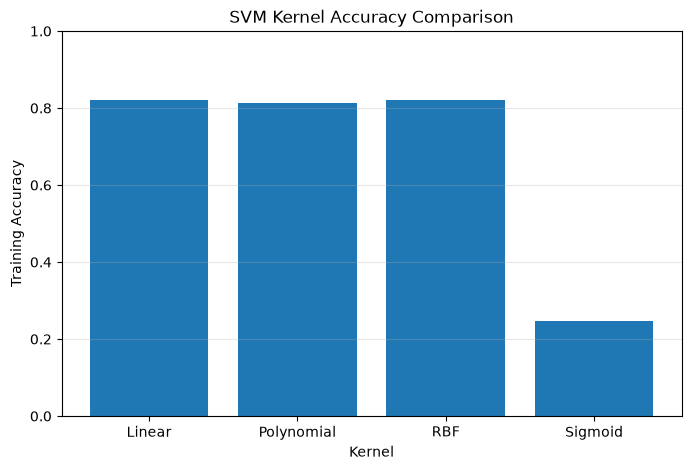

In [57]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Kernel"],
    results["Accuracy"]
)

plt.xlabel("Kernel")
plt.ylabel("Training Accuracy")
plt.title("SVM Kernel Accuracy Comparison")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()